# Beta, Market Regimes, and Portfolio Strategies
### Instructor version — completed Python solutions

**Research questions**
1. Are stock betas stable across market conditions?
2. Do high-beta stocks earn higher returns, or predict future returns?
3. Can historical betas help investors construct portfolios and manage market risk?

### Historical Sample and Empirical Design

We analyze U.S. stocks over **1995–2005**, a period that includes the technology boom, the subsequent stock market crash, and the recovery that followed.

The analysis is organized into three stages:

1. **Initial estimation (1995–1997):** We estimate stock betas using historical data available before the investment period.
2. **Out-of-sample evaluation (1998–2005):** We use these estimates to construct portfolios and evaluate their subsequent performance without using future information.
3. **Market regimes:** We distinguish three historical phases to examine how betas, stock returns, and portfolio performance change with market conditions:
   - **Bull 1:** January 1995–September 1, 2000.
   - **Bear:** September 2000–March 1, 2003.
   - **Bull 2:** March 2003–December 2005.

We use **daily log returns** throughout the exercise and the **SPY ETF** as a proxy for the U.S. stock market. Prices are adjusted for dividends and stock splits.

Market regimes are identified retrospectively. They are used to analyze historical performance, not to predict market turning points.



## Part 1 — Data Preparation and Market Regimes

### 1.1 Download and clean the data

**Task.** Use the same S&P 500 ticker list and market proxy (`SPY`). Download adjusted daily prices for 1995–2005. Remove stocks with **more than 10% missing observations** and then remove dates with any remaining missing prices. Display the final number of stocks and dates.


In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
from pandas_datareader import data as web

In [101]:
# S&P 500 ticker list: same GitHub CSV as the original notebook
url = ('https://raw.githubusercontent.com/alfonso-santos/'
       'microcredencial-carteras-python-2023/main/'
       'Tema_5_APT/data/sp500_tickers.csv')

# The original CSV stores the tickers as column names
stocks = pd.read_csv(url).columns.tolist()
print('Tickers in the source list:', len(stocks))

Tickers in the source list: 503


In [113]:
START_DATE = "1995-01-01"
END = "2006-01-01"

prices  =yf.download(stocks,START_DATE , END, auto_adjust= True, multi_level_index= False)["Close"]

indice = yf.download("SPY",START_DATE, END, auto_adjust= True, multi_level_index=False)["Close"]

[*********************100%***********************]  304 of 304 completed
[*********************100%***********************]  1 of 1 completed


In [115]:
indice = indice.rename("sp500")
market = indice.name

prices = prices.loc[:, prices.isna().mean() < 0.10]
stocks = prices.columns.to_list()


prices_final = pd.concat([prices,indice], axis = 1).dropna()

print(f"Number of stocks: {len(stocks)}")
print(f"Number of stocks: {len(prices_final)}")

Number of stocks: 304
Number of stocks: 2497


### 1.2 Calculate log returns and excess log returns

**Theory.** The empirical Market Model in this exercise is:

$$r_{i,t}-r_{f,t}=\alpha_i+\beta_i(r_{M,t}-r_{f,t})+\varepsilon_{i,t}.$$



#### Risk-Free Rate: 3-Month U.S. Treasury Securities

We use the **3-month U.S. Treasury yield** as a risk-free-rate proxy: short maturity limits interest-rate risk and Treasury credit risk is very low. The FRED series `DGS3MO` reports an annualized yield in percent.

For consistency with daily stock **log returns**, we use the approximation

$$r_{f,t} = \frac{\ln(1+y_t/100)}{252},$$

where $y_t$ is the quoted annualized yield and 252 represents trading days per year. This interprets the quoted annualized yield approximately as an effective annual return.

In [116]:
# Daily log returns for the retained stocks and the market
returns = np.log(prices_final).diff().dropna()

In [118]:
# Annualized 3-month Treasury yields (%), then approximate daily log RF
rf = web.DataReader('DGS3MO', 'fred', start=START_DATE, end=END)
rf_daily = np.log(1 + rf['DGS3MO'].ffill() / 100) / 252
rf_daily = rf_daily.reindex(returns.index).ffill()
rf_daily.name = 'RF'

In [119]:
# Excess daily log returns for stocks and the market
excess_returns = returns.sub(rf_daily, axis=0).dropna()

### 1.3 Identify historical market regimes

**Task.** Plot adjusted SPY prices and mark the two dates used in the original teaching exercise: **September 1, 2000** and **March 1, 2003**. Use these boundaries to compare an initial bull market, a bear-market episode, and the subsequent recovery.

**Important:** the boundaries are preselected **in hindsight** for illustration. They are not signals that were available in advance. The chosen dates are approximate historical phase boundaries, not algorithmically estimated price extrema.

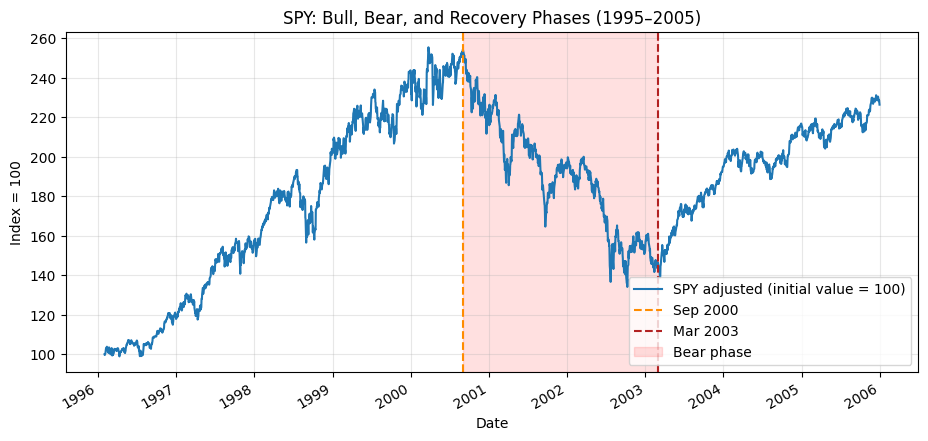

In [120]:
market_prices = prices_final[market]

# Fixed historical boundaries from the original notebook
bear_start = pd.Timestamp('2000-09-01')
bear_finish = pd.Timestamp('2003-03-01')

ax = (100 * market_prices / market_prices.iloc[0]).plot(
    figsize=(11, 5), label='SPY adjusted (initial value = 100)')
ax.axvline(bear_start, color='darkorange', linestyle='--', label='Sep 2000')
ax.axvline(bear_finish, color='firebrick', linestyle='--', label='Mar 2003')
ax.axvspan(bear_start, bear_finish, color='red', alpha=0.12, label='Bear phase')
ax.set(title='SPY: Bull, Bear, and Recovery Phases (1995–2005)',
       ylabel='Index = 100')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Part 2 — Beta Estimation and Stability

### 2.1 Estimate betas for the entire sample

**Theory.** In the empirical Market Model, beta measures sensitivity to market excess log returns. The regression $R^2$ measures the fraction of stock excess-return variance explained by the market. The usual beta p-value tests $H_0: \beta=0$, not $\beta=1$.

**Task.** For each retained stock, estimate alpha, beta, their p-values and $R^2$. Plot (a) the distribution of betas and (b) beta versus $R^2$. All full-sample estimates are **descriptive**, not investable forecasts.

In [125]:
def estimate_betas(sample,stock_list):
  results = []

  for stock in stock_list:
    regression = sm.OLS(sample[stock],sm.add_constant(sample[market])).fit()
    results.append([stock, regression.params["const"],regression.pvalues["const"],
                   regression.params[market],regression.pvalues[market],
                   regression.rsquared])

  return pd.DataFrame(results,columns = ["Stock","Alpha", "Alpha p-value","Beta","Beta p-value","R-squared"]).set_index("Stock")

full_betas = estimate_betas(excess_returns,stocks)
display(full_betas.sort_values("Beta",ascending= False).head(10).round(6))

,Alpha,Alpha p-value,Beta,Beta p-value,R-squared
Stock,,,,,
NTAP,0.000528,0.551656,2.048856,0.0,0.238088
LRCX,-0.000141,0.860094,1.807031,0.0,0.230913
TER,-0.000376,0.613817,1.799823,0.0,0.254141
SCHW,0.000106,0.847630,1.777855,0.0,0.378734
SWKS,-0.000303,0.753534,1.756523,0.0,0.162470
KLAC,0.000013,0.985388,1.753796,0.0,0.256560
AMAT,0.000059,0.924205,1.695796,0.0,0.303732
ADI,0.000112,0.863823,1.654682,0.0,0.273657
CSCO,0.000067,0.893264,1.638365,0.0,0.386502


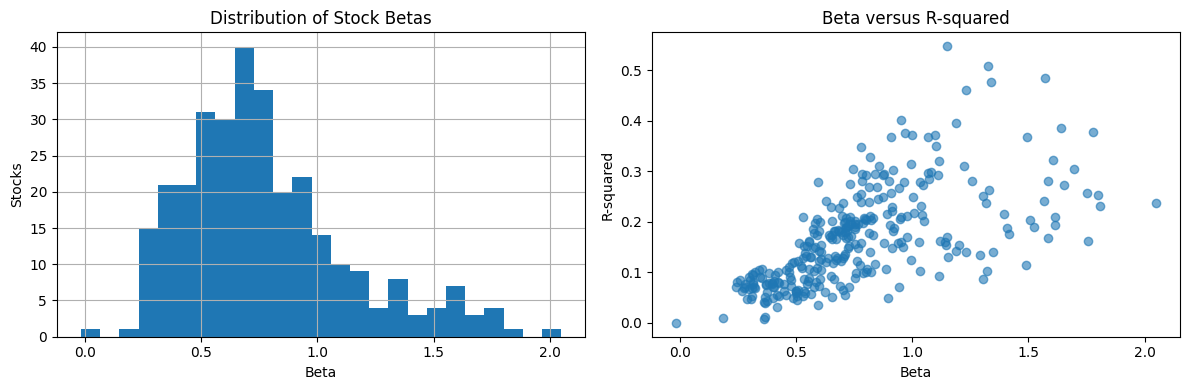

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
full_betas['Beta'].hist(bins=25, ax=axes[0])
axes[0].set(title='Distribution of Stock Betas', xlabel='Beta', ylabel='Stocks')

axes[1].scatter(full_betas['Beta'], full_betas['R-squared'], alpha=0.6)
axes[1].set(title='Beta versus R-squared', xlabel='Beta', ylabel='R-squared')
plt.tight_layout()
plt.show()

**Interpretation questions**
1. Why can two stocks have similar betas but very different $R^2$ values?
2. What does a non-significant alpha mean? Does a significant alpha prove mispricing?
3. Does a high beta necessarily imply high total volatility?

### 2.2 Estimate betas in successive bull and bear phases

**Task. Estimating Betas Across Market Regimes**

Does a stock's sensitivity to the market change between bull and bear markets?

Divide the sample into three historical periods:

- **Bull 1:** 1995–September 2000
- **Bear:** September 2000–March 2003
- **Bull 2:** March 2003–2005

For each period, estimate the Market Model for every stock and calculate **alpha, beta, their p-values, and \(R^2\)**.

Create a summary table comparing the average beta, average \(R^2\), and percentage of statistically significant betas (at the 5% level) across the three periods.

**Interpretation:** Are stocks generally more sensitive to market movements during bear markets? Does the market explain a larger proportion of stock return variability during downturns?

*Note:* Market phases are identified retrospectively. These estimates describe historical relationships and do not predict future market conditions.

In [128]:
phases = {"Bull 1": excess_returns.loc[:bear_start], # no pasa nada en dejar : excess_returns[:bear_start] pero mejor si se usa .loc
          "Bear": excess_returns.loc[bear_start:bear_finish],
          "Bull 2": excess_returns.loc[bear_finish:]}



phase_betas = {name: estimate_betas(sample,stocks)
               for name, sample in phases.items()}

# es una dictionary comprehension y es lo mismo que:
# phase_betas = {}
# for name, sample in phases.items():
#   phase_betas[name] = estimate_betas(sample, stocks)

summary = pd.DataFrame({name: [betas["Beta"].mean(),betas["R-squared"].mean(),(betas["Beta p-value"] < 0.05).mean(), len(phases[name])]
                        for name, betas in phase_betas.items()},index = ["Avg. Beta","Avg. R-Squared","Share of significant Betas","Numeber of days"])

display(summary.round(4))

,Bull 1,Bear,Bull 2
Avg. Beta,0.6823,0.8175,0.9931
Avg. R-Squared,0.1300,0.2152,0.2514
Share of significant Betas,0.9934,1.0000,1.0000
Numeber of days,1158.0000,623.0000,716.0000


### 2.3 Compare the same stocks across regimes

**Task. Comparing Betas Across Market Regimes**

Are stock betas stable over time, or do they change with market conditions?

Compare the estimated betas across the three market phases (**Bull 1, Bear, and Bull 2**).

1. Create three scatter plots: Bull 1 vs Bear, Bull 2 vs Bear, and Bull 1 vs Bull 2. Each point represents one stock.
2. Add a 45-degree line to each plot. Points above the line indicate that beta is higher in the period shown on the vertical axis.
3. Calculate the correlation between betas for each pair of periods.

**Interpretation.** Do stocks with high betas tend to remain high-beta stocks? Do betas generally increase or decrease across market phases? Are the betas in the two bull markets similar?

*Note:* Differences between estimated betas do not necessarily imply statistically significant changes. A formal test is required to establish whether two betas differ significantly.

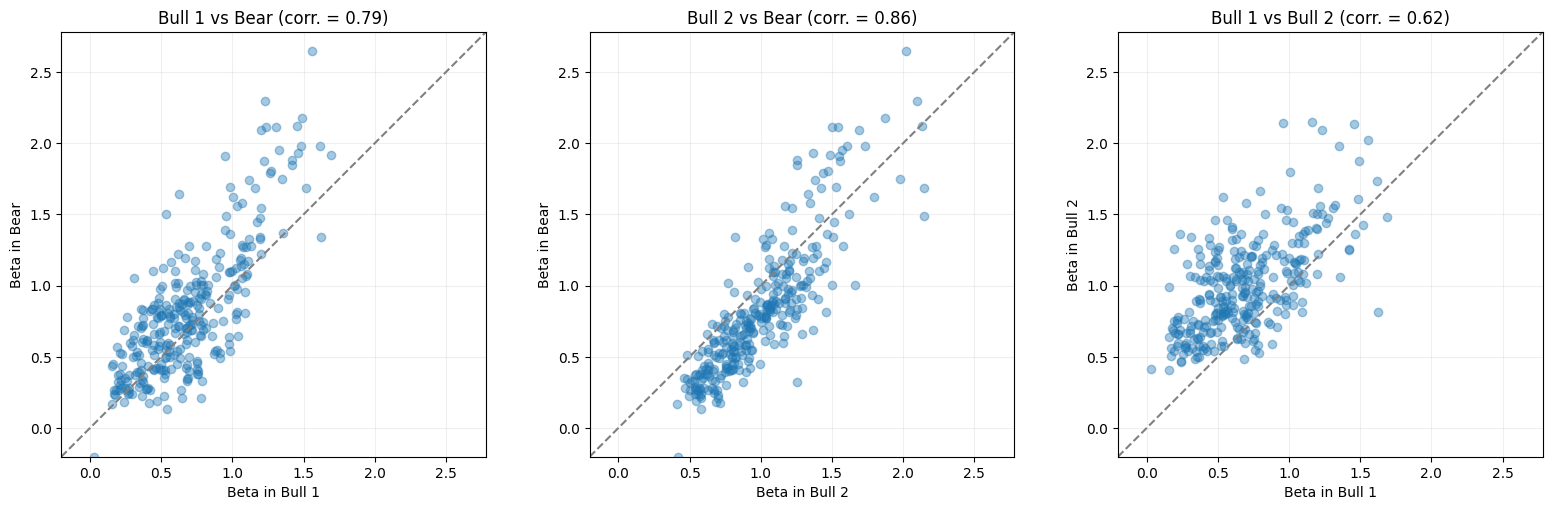

In [132]:
comparisons = [
    ('Bull 1', 'Bear'),
    ('Bull 2', 'Bear'),
    ('Bull 1', 'Bull 2')
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Common axis limits for all plots
all_betas = pd.concat([df['Beta'] for df in phase_betas.values()])
low = min(0, all_betas.min())
high = all_betas.max() * 1.05

for ax, (period1, period2) in zip(axes, comparisons):
    x = phase_betas[period1]['Beta']
    y = phase_betas[period2]['Beta']

    ax.scatter(x, y, alpha=0.4)

    # 45-degree line: equal betas in both periods
    ax.plot([low, high], [low, high], '--', color='gray')

    ax.set(
        xlabel=f'Beta in {period1}',
        ylabel=f'Beta in {period2}',
        title=f'{period1} vs {period2} (corr. = {x.corr(y):.2f})',
        xlim=(low, high),
        ylim=(low, high)
    )
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# Compare beta changes across market regimes
comparisons = [
    ('Bull 1', 'Bear'),
    ('Bull 2', 'Bear'),
    ('Bull 1', 'Bull 2')
]

results = []

for period1, period2 in comparisons:
    beta1 = phase_betas[period1]['Beta']
    beta2 = phase_betas[period2]['Beta']

    change = beta2 - beta1

    results.append([
        f'{period1} vs {period2}',
        beta1.corr(beta2),
        change.mean(),
        change.median(),
        100 * (change > 0).mean()
    ])

beta_changes = pd.DataFrame(
    results,
    columns=['Comparison', 'Correlation', 'Mean Change',
             'Median Change', '% Beta Increases']
).set_index('Comparison')

display(beta_changes.round(3))

,Correlation,Mean Change,Median Change,% Beta Increases
Comparison,,,,
Bull 1 vs Bear,0.786,0.135,0.116,68.092
Bull 2 vs Bear,0.860,-0.176,-0.217,16.776
Bull 1 vs Bull 2,0.619,0.311,0.294,86.184


In [ ]:
# Compare betas between bull and bear markets
beta_comparison = pd.DataFrame({
    'Beta Bull': phase_betas['Bull 1']['Beta'],
    'Beta Bear': phase_betas['Bear']['Beta']
})

# Calculate the change in beta
beta_comparison['Change'] = beta_comparison['Beta Bear'] - beta_comparison['Beta Bull']

# Select stocks whose beta did not increase
no_increase = beta_comparison[beta_comparison['Change'] <= 0]

# Display stocks sorted by the largest decrease
display(no_increase.sort_values('Change').round(3))

print('Number of stocks:', len(no_increase))
print('Percentage of stocks:', round(100 * len(no_increase) / len(beta_comparison), 1), '%')

,Beta Bull,Beta Bear,Change
Stock,,,
PG,0.780,0.212,-0.568
CL,0.788,0.328,-0.460
BMY,0.982,0.538,-0.444
MO,0.648,0.211,-0.437
LLY,0.915,0.489,-0.426
...,...,...,...
HRL,0.373,0.361,-0.011
CTAS,1.018,1.007,-0.011
HAS,0.682,0.671,-0.011


Number of stocks: 97
Percentage of stocks: 31.9 %


In [ ]:
display(no_increase.sort_values('Change', ascending=False).round(3))

,Beta Bull,Beta Bear,Change
Stock,,,
LH,0.660,0.657,-0.003
SPGI,0.552,0.542,-0.011
HAS,0.682,0.671,-0.011
CTAS,1.018,1.007,-0.011
HRL,0.373,0.361,-0.011
...,...,...,...
LLY,0.915,0.489,-0.426
MO,0.648,0.211,-0.437
BMY,0.982,0.538,-0.444


**Interpretation questions**
1. Are beta rankings stable between Bull 1, Bear, and Bull 2?
2. Is a change in beta necessarily caused by the market regime, or might the firm itself have changed?
3. Why does a p-value for beta being different from zero not test whether beta changed between periods?

## Part 3 — Beta and Stock Returns

### 3.1 Does beta explain historical average returns?

**Theory.** CAPM concerns **expected** returns in equilibrium, not a guaranteed ranking of **realized** returns in one historical period. A cross-sectional regression of realized average log returns on estimated betas is an informative classroom exercise, **not a formal CAPM validation test**.

### Task. Do High-Beta Stocks Earn Higher Returns?

According to the CAPM, stocks with higher systematic risk should offer higher **expected returns**. But does this relationship hold for the returns actually observed in our sample?

1. Calculate the **annualized average excess log return** for each stock over the full sample.
2. Create a scatter plot showing each stock's estimated beta (horizontal axis) and average excess return (vertical axis).
3. Estimate a cross-sectional regression of average excess returns on betas. Add the fitted regression line to the plot.
4. Report the slope, its **p-value**, and the **\(R^2\)**.

**Interpretation:** Is the relationship positive, as suggested by the CAPM? Is it statistically significant? How much of the variation in stock returns is explained by beta?

*Note:* The CAPM concerns expected returns, not realized returns in a particular historical period. This analysis illustrates the empirical relationship but is not a formal test of the CAPM.

### 3.2 Does the beta–return relationship change across regimes?

### Task. Does the Beta–Return Relationship Change Across Market Regimes?

We have examined the relationship between beta and stock returns over the full sample. But **does this relationship differ between bull and bear markets?**

Repeat the analysis separately for the three historical phases: **Bull 1, Bear, and Bull 2**.

1. Calculate each stock's average excess log return and beta within each phase.
2. Create three scatter plots showing the relationship between beta and average excess return, including a fitted regression line.
3. For each phase, report the regression slope, its **p-value**, and \(R^2\).

**Interpretation:** Is the relationship positive during bull markets and negative during bear markets? Is it equally strong in both bull markets? What do these results tell us about the relationship between systematic risk and realized returns?

*Note:* Betas and returns are calculated over the same periods. These results describe historical relationships, not the predictive power of beta.

### 3.3 Can historical beta predict future average returns?

### Task. Can Historical Betas Predict Future Stock Returns?

So far, we have estimated betas and analyzed returns using the same historical periods. But **can a beta estimated today help us identify stocks that will earn higher returns in the future?**

To investigate this question:

1. Estimate each stock's beta using **1995–1997** data only.
2. Calculate each stock's average annualized excess log return over **1998–2005**.
3. Create a scatter plot of historical betas against future average returns, including a fitted regression line.
4. Run a cross-sectional regression and report the slope, its **p-value**, and \(R^2\).

**Interpretation:** Do stocks with higher historical betas earn higher subsequent returns? Is the relationship statistically significant? How much of the variation in future returns can historical beta explain?

*Note:* Betas are estimated using information available before the evaluation period. This avoids using future returns to estimate the explanatory betas, but the analysis is still exploratory rather than a formal test of the CAPM.

**Interpretation questions**
1. Are the full-sample and out-of-sample slopes similar?
2. If the estimated slope is not statistically significant, what can—and cannot—we conclude?
3. Why might beta remain useful for **risk control** even if its relationship with future average returns is weak?

## Part 4. Portfolio Strategies Based on Beta

Can historical betas help investors construct portfolios with different risk exposures? And does updating beta estimates improve investment performance?

We will compare several strategies over **January 1998–December 2005**, starting with an initial investment of **100** and using SPY as the benchmark.

We will examine three approaches:

1. **Static High- and Low-Beta Portfolios:** Select stocks using betas estimated over 1995–1997 and hold them until the end of 2005 without rebalancing.
2. **Perfect Market Timing:** Invest in high-beta stocks during bull markets and low-beta stocks during bear markets. Market turning points are identified retrospectively, so this strategy is **not implementable in practice**.
3. **Rolling Beta Portfolios:** Re-estimate betas using the previous 36 months of data, select high- and low-beta stocks, and rebalance monthly.

All implementable strategies must use only information available at the time of each investment decision.

### 4.1. Selecting High- and Low-Beta Stocks

**Task.** Imagine you are an investor at the end of 1997 and want to construct two portfolios with different exposures to market risk.

1. Using betas estimated over **1995–1997**, identify the **10 stocks with the highest betas** and the **10 with the lowest betas**.
2. Display their estimated betas, beta p-values, and \(R^2\).
3. Compare the two groups and discuss whether the selected stocks are consistent with their business characteristics.

**Interpretation:** Do the two groups exhibit clearly different sensitivities to the market? Are the estimated betas statistically significant? What are the limitations of relying on historical betas to select stocks for future investment?

*Note:* Each portfolio initially allocates equal capital to its ten stocks. In a buy-and-hold strategy, the portfolio weights subsequently change with stock performance; they are not reset to equal weights.

### 4.1 Select high- and low-beta stocks using 1995–1997

**Task.** Rank the stocks by their initial betas and select the ten highest- and ten lowest-beta stocks. Display their beta, beta p-value and $R^2$. Consider whether statistically weak betas should influence interpretation.

### 4.2 Static buy-and-hold portfolios

### Task. Buy-and-Hold Portfolios: High Beta vs. Low Beta

Do stocks with higher historical betas deliver better investment performance? How do high- and low-beta portfolios behave during bull and bear markets?

1. At the beginning of **1998**, invest equally in the ten highest-beta stocks and the ten lowest-beta stocks selected in the previous exercise.
2. Hold both portfolios until **December 2005**, without rebalancing. Allow portfolio weights to change as stock prices evolve.
3. Calculate the daily portfolio values, starting from **100**, and plot their evolution alongside the adjusted SPY benchmark.

**Interpretation:** Which portfolio performs better during each market phase? Does the low-beta portfolio provide better protection during the bear market? Which strategy delivers the highest cumulative return over the full investment period?


In [ ]:
# Calculate cumulative wealth


### 4.3 Perfect-hindsight market timing (non-investable)

**Task.** Use the *same baskets selected in 1997*. Hold high-beta stocks in Bull 1, low-beta stocks in Bear, and high-beta stocks in Bull 2. Switch on the retrospective boundary dates used in Part 1.

**Key distinction:** This strategy assumes we know the change of regime in advance. It is an illustration of an oracle strategy, not a realistic investment rule. We rebalance the chosen basket to equal weights each time we switch.

### 4.4 Rolling beta and monthly rebalancing

**Task.** From January 1998, estimate each stock's beta using the **preceding 36 calendar months** of daily excess log returns. Each month, select ten high-beta and ten low-beta stocks and invest equal amounts at the start of the month. Let weights drift within the month.

**Theory:** With an OLS intercept, the beta estimate is covariance with market excess log returns divided by the market variance. The portfolio selection must only use observations available before its holding month.

**Interpretation questions**
1. Does updating betas improve performance relative to static buy and hold?
2. Do high- and low-beta portfolios behave differently during the 2000–2003 bear market?
3. How could turnover and transaction costs change the ranking of strategies?
4. Why is the hindsight strategy not evidence of a successful implementable timing rule?

## Part 5 — Portfolio Performance and Financial Interpretation

### 5.1 Compare portfolio performance

**Task.** Report cumulative return, annualized daily **log-return** volatility, a log Sharpe-like measure, maximum drawdown, realized beta, and market-model $R^2$ for every strategy.

Use the daily log risk-free return in the excess-return regression. Wealth is $\exp(\sum_t r_{p,t})$, and drawdown is computed from wealth. SPY adjusted prices are the common market benchmark; trading costs are excluded.

**Note:** the perfect-hindsight strategy is non-investable; universe selection is not free from historical bias.

### 5.2 How do the strategies perform in each market phase?

**Task.** Report cumulative performance during **Bull 1 (1998–Sep 2000)**, **Bear (Sep 2000–Mar 2003)**, and **Bull 2 (Mar 2003–2005)**. The phase boundaries come from retrospective classification.

dict_keys(['Bull 1', 'Bear', 'Bull 2'])

,Bull 1,Bear,Bull 2
High beta: buy & hold,345.68,-70.91,72.32
Low beta: buy & hold,72.87,31.35,94.01
SPY (adjusted),61.65,-42.40,54.58
Perfect hindsight (oracle),345.68,51.68,92.78
Rolling high beta,370.81,-59.14,147.52
Rolling low beta,-2.75,20.28,162.90


### 5.3 Does estimated beta predict *realized portfolio beta*?

**Task.** Compare the average stock beta estimated in **1995–1997** for each initial basket with its realized portfolio beta over **1998–2005**. The fixed buy-and-hold baskets change their weights over time.

### 5.4 Final discussion — submit written answers

1. **Beta and returns:** Is the cross-sectional relationship between beta and historical returns positive and statistically significant? Does it persist when betas are estimated before future returns? Why is this not a definitive CAPM test?
2. **Beta stability:** Are stocks' betas similar across the 1995–2000, 2000–2003 and 2003–2005 phases?
3. **Portfolio risk:** Do high- and low-beta portfolios achieve different realized market exposures? Does the low-beta portfolio protect during the decline?
4. **Static versus rolling:** Does monthly re-estimation improve risk or return? What would trading costs do?
5. **Interpretation:** Which results are retrospective descriptions, and which strategies could have been implemented? What are the limitations of the historical ticker list and the sample-wide NaN filter?

**Instructor note:** Do not require a predetermined beta–return relationship; students should interpret the empirical evidence they find.

### Methodological references and data sources

- Sharpe, W. F. (1964). *Capital Asset Prices: A Theory of Market Equilibrium under Conditions of Risk*. **The Journal of Finance**, 19(3), 425–442.
- Fama, E. F., & MacBeth, J. D. (1973). *Risk, Return, and Equilibrium: Empirical Tests*. **Journal of Political Economy**, 81(3), 607–636. (Background; we do not implement Fama–MacBeth.)
- SPY adjusted prices via Yahoo Finance / `yfinance`.
- Historical ticker-list CSV: https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python-2023/main/Tema_5_APT/data/sp500_tickers.csv
- FRED: 3-Month Treasury Constant Maturity Rate (`DGS3MO`), https://fred.stlouisfed.org/series/DGS3MO